<a href="https://colab.research.google.com/github/wendymarquez257/M-todos-Num-ricos-I/blob/main/M%C3%A9todo%20de%20Neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Análisis Numérico: Interpolación Iterada de Neville
**Algoritmo 3.1 (Página 91) y Ejemplo 2 (Página 89) — Burden & Faires**

- **Alumna:** Wendy Aidee Márquez Muñoz
- **Institución:** Instituto Politécnico Nacional (IPN)
- **Escuela:** Escuela Superior de Física y Matemáticas (ESFM)

---


##1. Formulación del Problema y Método de Neville

El **método de Neville** es un esquema iterativo que permite evaluar un polinomio de interpolación $P(x)$ en un punto específico $x$, utilizando $n + 1$ nodos distintos $x_0, x_1, \dots, x_n$ y sus valores conocidos $f(x_0), f(x_1), \dots, f(x_n)$, sin necesidad de construir algebraicamente el polinomio.

El algoritmo construye de forma recursiva una tabla triangular inferior $Q$ bajo las siguientes reglas:

1. **Inicialización (Columna $0$):**
   $$Q_{i,0} = f(x_i), \quad \text{para } i = 0, 1, \dots, n$$

2. **Fórmula de recurrencia:** Para $i = 1, 2, \dots, n$ y $j = 1, 2, \dots, i$:
   $$Q_{i,j} = \frac{(x - x_{i-j}) Q_{i,j-1} - (x - x_i) Q_{i-1,j-1}}{x_i - x_{i-j}}$$

3. **Aproximación final:** El resultado buscado corresponde a la última entrada calculada:
   $$P(x) = Q_{n,n}$$

###Definición del Ejemplo 2 (Página 89)
Queremos aproximar el valor de $f(1.5)$ utilizando los cinco puntos ($n = 4$) de la **Tabla 3.5**:

| $i$ | $x_i$ | $f(x_i) = Q_{i,0}$ |
| :---: | :---: | :---: |
| $0$ | $1.0$ | $0.7651977$ |
| $1$ | $1.3$ | $0.6200860$ |
| $2$ | $1.6$ | $0.4554022$ |
| $3$ | $1.9$ | $0.2818186$ |
| $4$ | $2.2$ | $0.1103623$ |

---

In [34]:
import numpy as np
import matplotlib.pyplot as plt

In [35]:
def metodo_neville(x, nodos_x, valores_y):

    m=len(nodos_x)
    Q=np.zeros((m, m), dtype=float)

    Q[:, 0]=valores_y

    for i in range(1, m):
        for j in range(1, i+1):
            numerador=(x-nodos_x[i-j])*Q[i, j-1]-(x-nodos_x[i])*Q[i-1, j-1]
            denominador=nodos_x[i]-nodos_x[i-j]
            Q[i,j]=numerador/denominador


    return Q, Q[-1, -1]

x_eval=1.5
x_datos=[1.0, 1.3, 1.6, 1.9, 2.2]
y_datos=[0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

Q, resultado=metodo_neville(x_eval, x_datos, y_datos)

print(f"{'x_i':<6} | {'Q_{i,0}':<10} | {'Q_{i,1}':<10} | {'Q_{i,2}':<10} | {'Q_{i,3}':<10} | {'Q_{i,4}':<10}")
print("-"*71)
for i in range(len(x_datos)):
    fila=f"{x_datos[i]:<6.1f} | " + " | ".join(f"{Q[i,j]:<10.7f}" for j in range(i + 1))
    print(fila)

print("-"*71)
print(f"Solución: P({x_eval})=Q_4,4={resultado:.7f}")

x_i    | Q_{i,0}    | Q_{i,1}    | Q_{i,2}    | Q_{i,3}    | Q_{i,4}   
-----------------------------------------------------------------------
1.0    | 0.7651977 
1.3    | 0.6200860  | 0.5233449 
1.6    | 0.4554022  | 0.5102968  | 0.5124715 
1.9    | 0.2818186  | 0.5132634  | 0.5112857  | 0.5118127 
2.2    | 0.1103623  | 0.5104270  | 0.5137361  | 0.5118302  | 0.5118200 
-----------------------------------------------------------------------
Solución: P(1.5)=Q_4,4=0.5118200


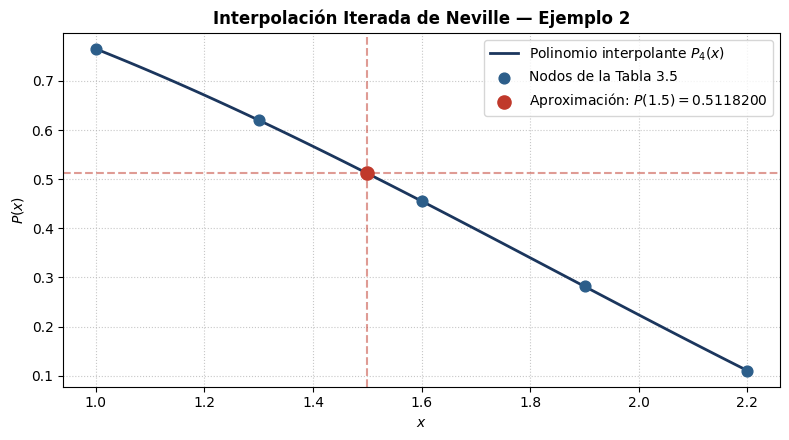

In [36]:
x_malla=np.linspace(1.0, 2.2, 100)
y_malla=[metodo_neville(xi, x_datos, y_datos)[1] for xi in x_malla]

plt.figure(figsize=(8, 4.5))
plt.plot(x_malla, y_malla, color='#1B365D', linewidth=2, label='Polinomio interpolante $P_4(x)$')
plt.scatter(x_datos, y_datos, color='#2C5E8A', s=60, zorder=5, label='Nodos de la Tabla 3.5')
plt.scatter([x_eval], [resultado], color='#C0392B', s=90, zorder=6, label=f'Aproximación: $P(1.5) = {resultado:.7f}$')

plt.axvline(x_eval, color='#C0392B', linestyle='--', alpha=0.5)
plt.axhline(resultado, color='#C0392B', linestyle='--', alpha=0.5)

plt.title('Interpolación Iterada de Neville — Ejemplo 2', fontweight='bold')
plt.xlabel('$x$')
plt.ylabel('$P(x)$')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

---
##Conclusión

La tabla generada por el programa reproduce con exactitud los valores de la **Tabla 3.6** de Burden:

- **Grado 1 ($j = 1$):** $Q_{1,1} = 0.5233449$, $Q_{2,1} = 0.5102968$, $Q_{3,1} = 0.5132634$, $Q_{4,1} = 0.5104270$.
- **Grado 2 ($j = 2$):** $Q_{2,2} = 0.5124715$, $Q_{3,2} = 0.5112857$, $Q_{4,2} = 0.5137361$.
- **Grado 3 ($j = 3$):** $Q_{3,3} = 0.5118127$, $Q_{4,3} = 0.5118302$.

> **Solución Final:**
> El valor aproximado del polinomio de interpolación evaluado en $x = 1.5$ es:
> $$P(1.5) = Q_{4,4} = \mathbf{0.5118200}$$

